# Libraries

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import neighbors, datasets
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text, plot_tree
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Data

## Air Pollution Data

In [1]:
def read_files(file_paths: list, drop_columns: list):
    dfs = [
        pd.read_csv(file).assign(year=int(file[-8:-4])).drop(columns=drop_columns)
        for file in file_paths
    ]

    df = pd.concat(dfs, ignore_index=True)

    return df

In [54]:
filenames_pollutants = ["data/ugz_ogd_air_d1_2024.csv"]

df_pollutants = read_files(file_paths=filenames_pollutants, drop_columns=["Status", "Intervall"])

In [55]:
df_pollutants.head()

,Datum,Standort,Parameter,Einheit,Wert,year
0,2024-01-01T00:00+0100,Zch_Stampfenbachstrasse,SO2,µg/m3,1.06,2024
1,2024-01-01T00:00+0100,Zch_Stampfenbachstrasse,CO,mg/m3,0.19,2024
2,2024-01-01T00:00+0100,Zch_Stampfenbachstrasse,NOx,ppb,6.23,2024
3,2024-01-01T00:00+0100,Zch_Stampfenbachstrasse,NO,µg/m3,1.55,2024
4,2024-01-01T00:00+0100,Zch_Stampfenbachstrasse,NO2,µg/m3,9.53,2024


In [4]:
param_units_pollutants = (
    df_pollutants[["Parameter", "Einheit"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

param_units_pollutants

,Parameter,Einheit
0,SO2,µg/m3
1,CO,mg/m3
2,NOx,ppb
3,NO,µg/m3
4,NO2,µg/m3
5,O3,µg/m3
6,PM10,µg/m3
7,PM2.5,µg/m3
8,O3_max_h1,µg/m3
9,O3_nb_h1>120,1


In [87]:
df_pollutants_pivot = (
    df_pollutants
    .pivot(index=["Datum", "Standort"], columns="Parameter", values="Wert")
    .reset_index()
    .loc[:, ["Standort", "NO2", "O3", "PM2.5"]]
)

df_pollutants_pivot.columns.name = None

df_pollutants_pivot["Standort_code"] = (
    df_pollutants_pivot["Standort"].astype("category").cat.codes
)

df_pollutants_pivot.tail()

,Standort,NO2,O3,PM2.5,Standort_code
1459,Zch_Stampfenbachstrasse,34.43,6.90,14.94,3
1460,Zch_Heubeeribüel,28.53,13.42,13.36,0
1461,Zch_Rosengartenstrasse,40.10,5.97,21.01,1
1462,Zch_Schimmelstrasse,38.21,7.71,18.57,2
1463,Zch_Stampfenbachstrasse,35.57,7.55,17.44,3


In [57]:
df_pollutants_pivot.describe()

,NO,NO2,NOx,O3,PM10,PM2.5
count,1411.000000,1411.000000,1411.000000,1420.000000,1421.000000,1421.000000
mean,9.526492,20.093912,18.145415,49.057789,11.449078,7.440929
std,10.769495,10.793531,13.536379,23.652550,6.539511,4.778085
min,0.490000,2.360000,1.750000,1.430000,1.850000,0.930000
25%,1.935000,11.405000,7.685000,29.955000,6.680000,3.790000
50%,6.180000,19.620000,15.550000,52.570000,10.110000,6.110000
75%,13.175000,27.205000,25.085000,66.175000,14.790000,10.060000
max,97.540000,61.810000,110.520000,117.240000,52.020000,30.690000


In [104]:
df_pollutants_pivot = df_pollutants_pivot.dropna()

df_pollutants_pivot.describe()

,NO2,O3,PM2.5,Standort_code
count,1408.000000,1408.000000,1408.000000,1408.000000
mean,20.089318,49.280142,7.423984,1.506392
std,10.791642,23.581315,4.779382,1.134189
min,2.360000,1.430000,0.930000,0.000000
25%,11.407500,30.825000,3.777500,0.000000
50%,19.590000,52.760000,6.080000,2.000000
75%,27.185000,66.222500,10.040000,3.000000
max,61.810000,117.240000,30.690000,3.000000


## Traffic Data

In [29]:
df_traffic = pd.read_csv("data/traffic_data_2023_2024.csv")

In [30]:
df_traffic.head()

,ZSName,MessungDatZeit,AnzFahrzeuge,year,pollutant_station
0,Rosengartenstrasse (Nordstrasse),2023-01-01T00:00:00,688.0,2023,Zch_Rosengartenstrasse
1,Rosengartenstrasse (Nordstrasse),2023-01-01T01:00:00,1370.0,2023,Zch_Rosengartenstrasse
2,Rosengartenstrasse (Nordstrasse),2023-01-01T02:00:00,1041.0,2023,Zch_Rosengartenstrasse
3,Rosengartenstrasse (Nordstrasse),2023-01-01T03:00:00,661.0,2023,Zch_Rosengartenstrasse
4,Rosengartenstrasse (Nordstrasse),2023-01-01T04:00:00,528.0,2023,Zch_Rosengartenstrasse


# Modelling

In [116]:
X = df_pollutants_pivot[["NO2", "O3", "PM2.5"]]
y = df_pollutants_pivot["Standort_code"]

0       0
1       1
2       2
3       3
4       0
       ..
1459    3
1460    0
1461    1
1462    2
1463    3
Name: Standort_code, Length: 1408, dtype: int8

## Base-line Model

### kNN

In [119]:
# Standard-scalar of the features
# (in this case, maybe not really necessary)
from sklearn.preprocessing import StandardScaler
# X = StandardScaler().fit_transform(X)

n_neighbours = 5

# create an instance of Neighbor Classifier and fit the data
clf = neighbors.KNeighborsClassifier(n_neighbours, weights='uniform')
clf.fit(X, y)
accuracy_score(y, clf.predict(X))

0.6612215909090909

### PCA

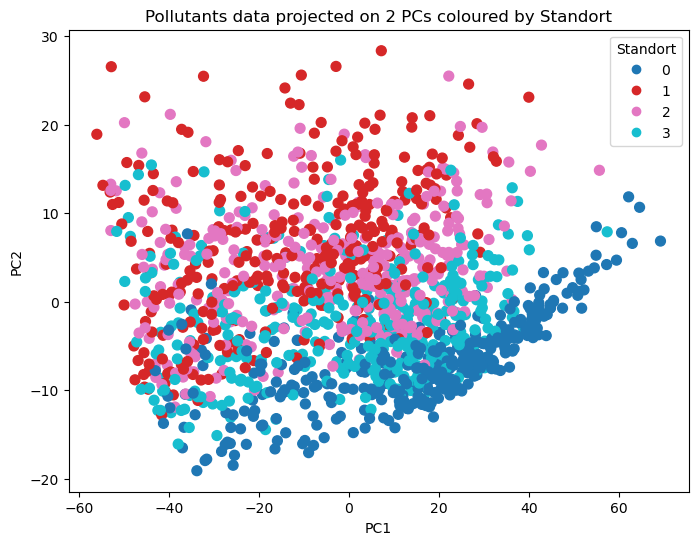

In [121]:
# X = features, y = Standort codes
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_2d[:,0], X_2d[:,1], c=y, cmap='tab10', s=50)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Pollutants data projected on 2 PCs coloured by Standort')
plt.legend(*scatter.legend_elements(), title="Standort")
plt.show()

### LDA

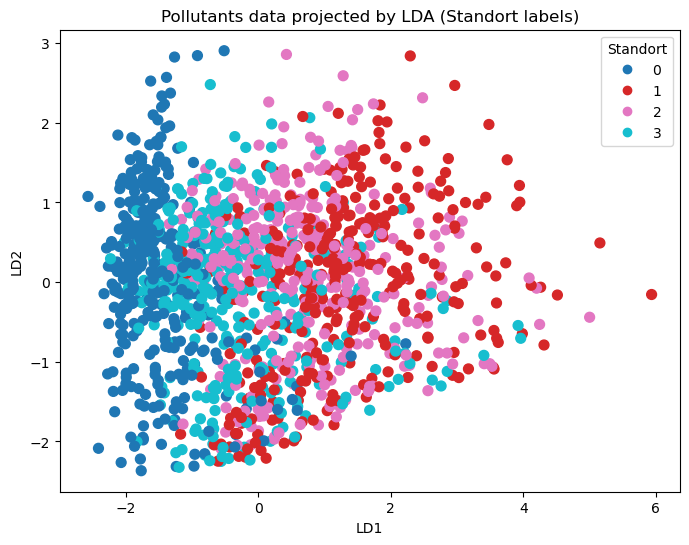

In [122]:
# X = features, y = Standort codes
lda = LDA(n_components=2)  # max n_components = n_classes - 1
X_lda = lda.fit_transform(X, y)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_lda[:,0], X_lda[:,1], c=y, cmap='tab10', s=50)
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.title('Pollutants data projected by LDA (Standort labels)')
plt.legend(*scatter.legend_elements(), title="Standort")
plt.show()

## Sophisticated Approach

### Decision Tree

In [88]:
df_pollutants_pivot.head()

,Standort,NO2,O3,PM2.5,Standort_code
0,Zch_Heubeeribüel,4.64,64.42,3.74,0
1,Zch_Rosengartenstrasse,24.75,40.86,6.10,1
2,Zch_Schimmelstrasse,13.36,55.08,4.53,2
3,Zch_Stampfenbachstrasse,9.53,56.41,5.28,3
4,Zch_Heubeeribüel,4.13,64.58,1.37,0


In [90]:
# build and train the model
decision_tree = DecisionTreeClassifier(random_state=0, max_depth=None)
# random_state hyperparameter makes the models output replicable
# max_depth (reducing depth might help against overfitting and increase speed)
decision_tree = decision_tree.fit(df_pollutants_pivot.iloc[:, 1:-1], df_pollutants_pivot.iloc[:, -1:])

In [84]:
print(df_pollutants_pivot["Standort"].drop_duplicates())

0           Zch_Heubeeribüel
1     Zch_Rosengartenstrasse
2        Zch_Schimmelstrasse
3    Zch_Stampfenbachstrasse
Name: Standort, dtype: object


In [91]:
# print out the learned decision rules as a text
r = export_text(decision_tree, feature_names=["NO2", "O3", "PM2.5"])
print(r)

|--- NO2 <= 13.14
|   |--- NO2 <= 7.47
|   |   |--- NO2 <= 6.69
|   |   |   |--- O3 <= 85.24
|   |   |   |   |--- O3 <= 84.96
|   |   |   |   |   |--- PM2.5 <= 7.33
|   |   |   |   |   |   |--- O3 <= 76.17
|   |   |   |   |   |   |   |--- O3 <= 75.36
|   |   |   |   |   |   |   |   |--- PM2.5 <= 4.13
|   |   |   |   |   |   |   |   |   |--- O3 <= 62.86
|   |   |   |   |   |   |   |   |   |   |--- O3 <= 62.81
|   |   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |   |   |--- O3 >  62.81
|   |   |   |   |   |   |   |   |   |   |   |--- class: 3
|   |   |   |   |   |   |   |   |   |--- O3 >  62.86
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |--- PM2.5 >  4.13
|   |   |   |   |   |   |   |   |   |--- PM2.5 <= 4.21
|   |   |   |   |   |   |   |   |   |   |--- class: 3
|   |   |   |   |   |   |   |   |   |--- PM2.5 >  4.21
|   |   |   |   |   |   |   |   |   |   |--- O3 <= 61.07
|   |   |   |   |   |   |   |   |   

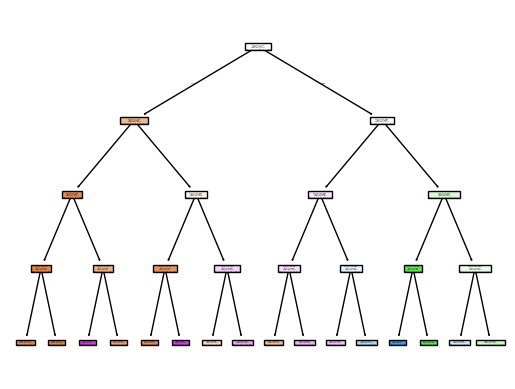

In [96]:
# plot the decision tree itself
decision_tree = DecisionTreeClassifier(random_state=0, max_depth=4)
decision_tree = decision_tree.fit(X, y)
t = plot_tree(decision_tree, filled=True)